# Week 4: Event Study and Abnormal Returns

How do our stocks react around quarterly earnings announcements? This notebook builds a leak-free event study following MacKinlay (1997), "Event Studies in Economics and Finance". Reusable functions live in `src/event_study.py`; tables and charts are saved to `reports/week4/`.

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../../src")
from event_study import EventStudyDesign, window_dates
from factor_utils import LISTING_DATES

RAW = "../../data/raw"
REPORTS = "../../reports/week4"
os.makedirs(REPORTS, exist_ok=True)

## Task 1: Event Study Methodology

The design below is fixed **before any event data is loaded**. Task 1 is committed to GitHub on its own, so the commit date shows the hypothesis was written down before any result existed.

### 1.1 Core concepts

| Term | Meaning in this study |
| --- | --- |
| Event date (day 0) | The first trading session in which the market can react to the announcement: the announcement day if it comes out before the 4:00 pm ET close, the next trading day if it comes out after the close |
| Estimation window | Trading days well before the event, used only to learn what a "normal" return looks like for that stock |
| Event window | Trading days around day 0 where the reaction is measured |
| Normal return | The return the stock would have earned that day without the event, from the normal-return model |
| Abnormal return (AR) | Actual return − normal return, for each day of the event window |
| Cumulative abnormal return (CAR) | Sum of the daily abnormal returns over a stated range of event days |

### 1.2 Event type: quarterly earnings announcements

- **Sample:** quarterly earnings announcements of our stock universe, July 2021 – August 2026 (about 20 quarters per stock).
- **Why earnings:** each stock reports four times a year on a known date, which gives many events (several hundred) for averaging, and the news is clearly about the company itself. Macro dates (CPI, FOMC) hit every stock on the same day, so their events are not independent and the market model would absorb most of the reaction.
- **Stocks:** the 48 US filers. TSM and ASML are left out: they are foreign filers, report on different forms and calendars, and trade mainly outside US hours.
- **Data (Task 2):** announcement date, time of day and EPS surprise (reported EPS vs analyst estimate) from yfinance's earnings calendar, cross-checked against the date of each company's SEC 8-K earnings filing (Item 2.02). The time of day decides day 0.

### 1.3 Windows (trading days relative to day 0)

| Window | First day | Last day | Length | Purpose |
| --- | --- | --- | --- | --- |
| Estimation | −250 | −30 | 221 days | Fit the normal-return model (about 10½ months of history) |
| Gap | −29 | −11 | 19 days | Left out on purpose (below) |
| Event | −10 | +10 | 21 days | Measure abnormal returns and plot the average pattern |
| Main test | −1 | +1 | 3 days | Pre-registered CAR for the hypothesis |
| Secondary test | +2 | +10 | 9 days | Drift after the announcement |

**Why the gap is enough:** the estimation window ends 29 trading days before day 0, and 19 trading days (about four weeks) before the event window opens. That keeps out (a) any pre-announcement run-up or information leakage, which usually builds in the last two weeks, and (b) the event window itself even if an announcement date is off by a day or two. The previous quarter's announcement is about 63 trading days earlier, so it can fall inside the estimation window: this is standard practice, and it only makes the normal-return variance slightly larger, which makes the later t-tests more conservative, not less.

**Why −1 to +1 for the main test:** most companies report after the close, so most of the reaction lands on day 0; day −1 catches announcements whose timing is recorded wrongly or that leak, and day +1 catches the slower part of the reaction. A window of 3 days keeps the noise of unrelated news small.

### 1.4 Normal-return model: market model

| Model | Normal return | Problem for our stocks |
| --- | --- | --- |
| Mean-adjusted | the stock's average return in the estimation window | ignores the market: a 2% market day is counted as a 2% "reaction" |
| Market-adjusted | the market's return that day (beta fixed at 1) | wrong when beta is far from 1: a beta-1.6 stock on a +2% market day is expected to move +3.2%, not +2% |
| **Market model** | α + β × market return, with α and β fitted on the estimation window | **chosen:** removes each stock's own market sensitivity |

The market is **SPY**, the same benchmark as Week 3. Section 1.7 shows why beta cannot be fixed at 1 here: our stocks' betas run from about 0.2 to 2.1. The market-adjusted model is kept as a robustness check in Task 3.

### 1.5 Pre-registered hypothesis and expected sign

- **H1 (main):** the market reacts in the direction of the earnings surprise. Mean CAR(−1, +1) is **positive** for positive EPS surprises and **negative** for negative surprises, and the difference between the two groups is positive.
- **H2 (secondary):** the reaction continues after the announcement (post-earnings announcement drift, Bernard and Thomas 1989): mean CAR(+2, +10) has the **same sign** as the surprise.
- **Test:** t-tests on the average CAR across events at the 5% level, with 95% confidence intervals (Task 4).
- **Economic relevance:** a result is only called economically meaningful if the average CAR is larger than an assumed round-trip trading cost of **20 basis points**; smaller but significant effects are reported as economically marginal.
- **Null result:** if neither group's CAR differs from zero, H1 is rejected and reported as such.

### 1.6 The design in code
`EventStudyDesign` in `src/event_study.py` holds every boundary, and `validate()` stops if the estimation and event windows overlap, the gap is under 10 days, the estimation window is under 200 days, or a test window falls outside the event window.

In [2]:
DESIGN = EventStudyDesign().validate()
DESIGN.table()

,first day,last day,trading days
window,,,
Estimation window,-250,-30,221
Gap (not used),-29,-11,19
Event window,-10,10,21
Main test: CAR,-1,1,3
Secondary test: drift CAR,2,10,9


**Check:** a design whose estimation window runs into the event window must be refused.

In [3]:
for bad in [EventStudyDesign(est_end=-5),           # estimation overlaps the event window
            EventStudyDesign(est_end=-15)]:         # no overlap, but only a 4-day gap
    try:
        bad.validate()
        print("accepted (should not happen)")
    except AssertionError as e:
        print("refused:", e)

refused: estimation window overlaps the event window
refused: gap of 4 days is below the minimum of 10


### 1.7 Why beta cannot be fixed at 1
Daily beta and R² of each stock against SPY over the whole sample (July 2021 – August 2026). These are design inputs only: no event data is used.

In [4]:
prices = pd.read_csv(f"{RAW}/prices_2020.csv", parse_dates=["date"])
spy = pd.read_csv(f"{RAW}/spy_2020.csv", parse_dates=["date"]).set_index("date")["adj_close"]
px = prices.pivot(index="date", columns="ticker", values="adj_close")
for tk, d in LISTING_DATES.items():                 # RKLB traded as a SPAC before listing (Week 2)
    px.loc[px.index < pd.Timestamp(d), tk] = np.nan
stock_ret = px.pct_change(fill_method=None)
mkt_ret = spy.pct_change()
both = stock_ret.loc["2021-07-01":"2026-08-31"].join(mkt_ret.rename("SPY"), how="inner")

beta = both.drop(columns="SPY").apply(lambda s: s.cov(both["SPY"]) / both["SPY"].var())
r2 = both.drop(columns="SPY").apply(lambda s: s.corr(both["SPY"]) ** 2)
beta_tbl = pd.DataFrame({"beta": beta, "R²": r2}).sort_values("beta")
print(f"Betas range from {beta.min():.2f} ({beta.idxmin()}) to {beta.max():.2f} ({beta.idxmax()}); "
      f"{((beta < 0.8) | (beta > 1.2)).sum()} of {len(beta)} stocks are outside 0.8–1.2. Median R²: {r2.median():.2f}.")
pd.concat([beta_tbl.head(5), beta_tbl.tail(5)]).round(2)

Betas range from 0.17 (JNJ) to 2.14 (RKLB); 35 of 50 stocks are outside 0.8–1.2. Median R²: 0.29.


,beta,R²
JNJ,0.17,0.03
KO,0.26,0.07
PEP,0.28,0.06
MRK,0.28,0.04
PG,0.28,0.07
SMCI,2.02,0.15
PLTR,2.07,0.28
NVDA,2.13,0.49
AMD,2.14,0.41
RKLB,2.14,0.19


### 1.8 The windows on a real calendar
`window_dates()` maps the design onto actual trading days for one event. The example uses day 0 = 2 August 2024, only to show the calendar; it is not an event from the sample. An event that does not have 250 trading days of history before it, or 10 after it, is dropped (Task 2), never truncated. Saved to `reports/week4/event_windows.png`.

In [5]:
calendar = pd.DatetimeIndex(sorted(prices["date"].unique()))
ex = window_dates(calendar, "2024-08-02", DESIGN)
pd.Series({k: v.date() for k, v in ex.items()}, name="date").to_frame()

,date
est_first,2023-08-04
est_last,2024-06-20
event_first,2024-07-19
day0,2024-08-02
event_last,2024-08-16


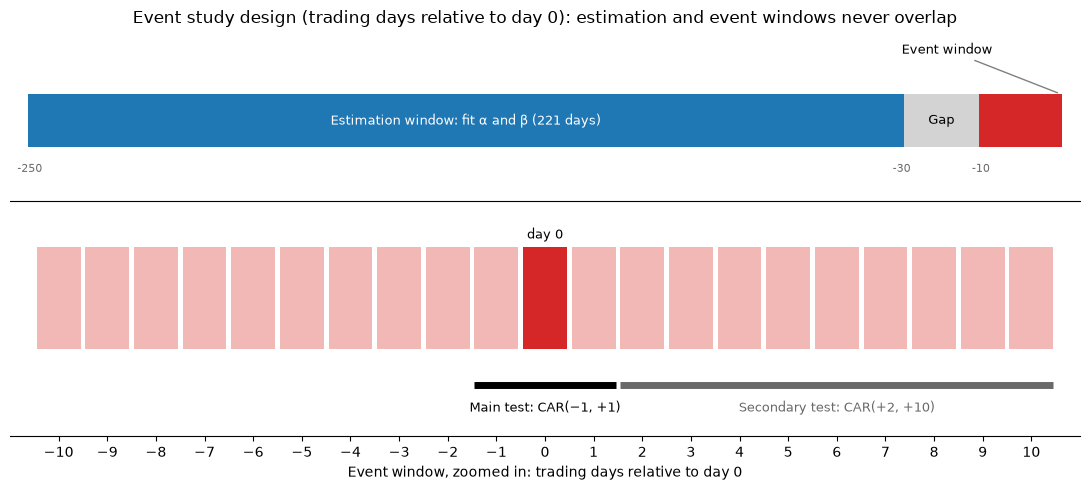

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 5), gridspec_kw={"height_ratios": [1, 1.3]})
D = DESIGN
# top: the whole design
for label, a, b, col, tc in [("Estimation window: fit α and β (221 days)", D.est_start, D.est_end, "C0", "white"),
                             ("Gap", D.est_end + 1, D.event_start - 1, "lightgray", "black"),
                             ("", D.event_start, D.event_end, "C3", "white")]:
    ax1.barh(0, b - a + 1, left=a - 0.5, height=0.6, color=col)
    if label:
        ax1.text((a + b) / 2, 0, label, ha="center", va="center", fontsize=9, color=tc)
ax1.annotate("Event window", (D.event_end, 0.3), xytext=(D.event_end - 40, 0.75), fontsize=9,
             arrowprops={"arrowstyle": "-", "color": "gray"})
for d in [D.est_start, D.est_end, D.event_start]:
    ax1.text(d, -0.48, str(d), ha="center", va="top", fontsize=8, color="dimgray")
ax1.set_xlim(D.est_start - 5, D.event_end + 5)
ax1.set_ylim(-0.9, 1.0)
ax1.set_yticks([])
ax1.set_xticks([])
ax1.set_title("Event study design (trading days relative to day 0): estimation and event windows never overlap")
# bottom: zoom on the event window
days = np.arange(D.event_start, D.event_end + 1)
ax2.bar(days, 1, width=0.9, color=["C3" if d == 0 else "#f2b8b5" for d in days])
for (a, b), lbl, y, col in [(D.main_car, "Main test: CAR(−1, +1)", -0.35, "black"),
                            (D.drift_car, "Secondary test: CAR(+2, +10)", -0.35, "dimgray")]:
    ax2.plot([a - 0.45, b + 0.45], [y, y], lw=5, color=col, solid_capstyle="butt")
    ax2.text((a + b) / 2, y - 0.15, lbl, ha="center", va="top", fontsize=9, color=col)
ax2.text(0, 1.08, "day 0", ha="center", fontsize=9)
ax2.set_xticks(days)
ax2.set_xlim(D.event_start - 1, D.event_end + 1)
ax2.set_ylim(-0.85, 1.3)
ax2.set_yticks([])
ax2.set_xlabel("Event window, zoomed in: trading days relative to day 0")
for sp in ["left", "right", "top"]:
    ax2.spines[sp].set_visible(False)
    ax1.spines[sp].set_visible(False)
plt.tight_layout()
plt.savefig(f"{REPORTS}/event_windows.png", dpi=150)
plt.show()

### 1.9 Methodology note (summary)
- **Event:** quarterly earnings announcements of 48 US stocks from our universe, July 2021 – August 2026; day 0 = first session that can react (after-close announcements move to the next trading day).
- **Windows (trading days):** estimation −250 to −30 (221 days); gap −29 to −11 (19 days); event −10 to +10 (21 days). The estimation window always ends before the event window starts, enforced in code.
- **Normal-return model:** market model with SPY, α and β fitted per event on its own estimation window; betas in our universe range far from 1, so the market-adjusted model is used only as a robustness check.
- **Hypothesis (pre-registered):** CAR(−1, +1) has the sign of the EPS surprise (H1); drift CAR(+2, +10) has the same sign (H2). Tested at the 5% level; called economically meaningful only above a 20 bp round-trip cost.

## Task 2: Event Data Preparation

Builds the clean event table and the per-event window table that the abnormal-return code (Task 3) will use. Downloads are cached in `data/raw/`, so the notebook only goes online the first time; the cleaned tables go to `data/events/`.

### 2.1 Download earnings dates and daily SPY
- **Earnings:** date, time of day, EPS estimate and reported EPS for the 48 US stocks from Yahoo Finance (`fetch_earnings_dates`), 40 quarters back. Cached in `data/raw/earnings_dates_raw.csv`.
- **Market:** daily SPY through September 2026, so even late-August events have their full +10-day window. Cached in `data/raw/spy_daily.csv` (the Week 3 SPY file is left untouched).

In [7]:
from event_study import (fetch_earnings_dates, classify_timing, align_day0, build_event_table,
                         build_window_table, check_no_leakage, fetch_8k_earnings_filings, cross_check_dates)

EVENTS = "../../data/events"
os.makedirs(EVENTS, exist_ok=True)
TICKERS = sorted(t for t in prices["ticker"].unique() if t not in ("TSM", "ASML"))

EARN_FILE = f"{RAW}/earnings_dates_raw.csv"
if os.path.exists(EARN_FILE):
    raw = pd.read_csv(EARN_FILE, parse_dates=["announce_ts"])
else:
    raw, failed = fetch_earnings_dates(TICKERS, limit=40)
    print("No data for:", failed or "none")
    raw.to_csv(EARN_FILE, index=False)

SPY_DAILY = f"{RAW}/spy_daily.csv"
if os.path.exists(SPY_DAILY):
    spy_d = pd.read_csv(SPY_DAILY, parse_dates=["date"])
else:
    import yfinance as yf
    s = yf.download("SPY", start="2020-01-01", end="2026-10-01", auto_adjust=False, progress=False)
    if isinstance(s.columns, pd.MultiIndex):
        s.columns = s.columns.get_level_values(0)
    spy_d = s.reset_index().rename(columns={"Date": "date", "Adj Close": "adj_close"})[["date", "adj_close"]]
    spy_d.to_csv(SPY_DAILY, index=False)

print(f"Earnings rows: {len(raw)} for {raw['ticker'].nunique()} of {len(TICKERS)} stocks, "
      f"{raw['announce_ts'].min():%Y-%m-%d} to {raw['announce_ts'].max():%Y-%m-%d}")
print(f"SPY daily: {spy_d['date'].min():%Y-%m-%d} to {spy_d['date'].max():%Y-%m-%d}")

Earnings rows: 2327 for 48 of 48 stocks, 2013-10-22 to 2027-02-02
SPY daily: 2020-01-02 to 2026-09-30


### 2.2 Daily returns and the trading calendar
Daily simple returns from adjusted closes for the stocks (RKLB set to missing before its listing, as in Weeks 2–3) and for SPY. The trading calendar is the set of days on which both the stocks and SPY have prices.

In [8]:
stock_ret = px.pct_change(fill_method=None)                     # px: prices with RKLB masked (section 1.7)
mkt_ret = spy_d.set_index("date")["adj_close"].pct_change().rename("SPY")
calendar = stock_ret.index.intersection(mkt_ret.dropna().index).sort_values()
stock_ret, mkt_ret = stock_ret.loc[calendar], mkt_ret.loc[calendar]
print(f"Trading calendar: {len(calendar)} days, {calendar[0]:%Y-%m-%d} to {calendar[-1]:%Y-%m-%d}")

Trading calendar: 1692 days, 2020-01-03 to 2026-09-28


### 2.3 Event table: align each announcement to its trading day
- **Time of day** from the announcement time stamp (New York time): before 9:30 am = before open; 9:30 am – 4:00 pm = during market; 4:00 pm or later = after close; 12 AM = time unknown.
- **Day 0:** the announcement date for before-open, during-market and unknown times; the **next** trading day for after-close. A weekend or holiday date moves to the next trading day.
- **Sample:** day 0 from 1 July 2021 to 31 August 2026, the period fixed in Task 1.
- **Surprise** = reported EPS − consensus estimate; its sign defines the groups for H1.

Saved to `data/events/earnings_events.csv`.

In [9]:
events, build_log = build_event_table(raw, calendar, "2021-07-01", "2026-08-31")
events.to_csv(f"{EVENTS}/earnings_events.csv", index=False)
display(pd.Series(build_log, name="count").to_frame())
display(events["timing"].value_counts().rename("events").to_frame())
events["surprise_sign"].value_counts().rename("events").to_frame()

,count
raw rows,2327
dropped: no reported EPS (future or missing),52
outside the sample period,1273
dropped: duplicate ticker and day 0,1
events kept,1001


,events
timing,
after close,536
before open,462
during market,3


,events
surprise_sign,
positive,839
negative,118
zero,43
no estimate,1


**Check: alignment examples.** One event of each timing type, plus any announcement dated on a weekend or holiday, showing the announcement time and the day 0 it was moved to.

In [10]:
ex = events.groupby("timing", group_keys=False).head(1)
non_trading = events[~events["announce_ts"].dt.normalize().isin(calendar)].head(2)
ex = pd.concat([ex, non_trading]).drop_duplicates("event_id")
ex = ex.assign(announce_day=ex["announce_ts"].dt.strftime("%a %Y-%m-%d %H:%M"), day0_day=ex["day0"].dt.strftime("%a %Y-%m-%d"))
ex[["ticker", "announce_day", "timing", "day0_day"]]

,ticker,announce_day,timing,day0_day
0,MU,Wed 2021-06-30 16:00,after close,Thu 2021-07-01
1,JPM,Tue 2021-07-13 06:00,before open,Tue 2021-07-13
57,TSLA,Wed 2021-10-20 15:00,during market,Wed 2021-10-20
393,CVX,Sun 2023-07-23 16:00,after close,Mon 2023-07-24


### 2.4 Cross-check the dates against SEC filings
Companies file an 8-K under Item 2.02 ("Results of Operations") when they release earnings. Each Yahoo announcement date is compared with the nearest such filing: **match** = filed between 1 day before and 3 days after; **mismatch** = a filing exists within 30 days but outside that range; **no 8-K** = none found. Mismatches are kept but flagged for the limitations in Task 5. Filings are cached in `data/raw/sec_8k_202.csv`.

In [11]:
SEC_FILE = f"{RAW}/sec_8k_202.csv"
try:
    if os.path.exists(SEC_FILE):
        filings = pd.read_csv(SEC_FILE, parse_dates=["filing_date"])
    else:
        filings = fetch_8k_earnings_filings(TICKERS, since="2021-01-01")
        filings.to_csv(SEC_FILE, index=False)
    events = cross_check_dates(events, filings)
    events.to_csv(f"{EVENTS}/earnings_events.csv", index=False)
    display(events["date_check"].value_counts().rename("events").to_frame())
    print("Gap (filing date − announcement date), days:")
    display(events["sec_gap_days"].value_counts().sort_index().rename("events").to_frame().T)
    display(events.loc[events["date_check"] != "match", ["event_id", "announce_ts", "timing", "sec_gap_days", "date_check"]].head(10))
except Exception as e:
    print(f"SEC cross-check skipped ({type(e).__name__}: {e})")

,events
date_check,
match,996
mismatch,4
no 8-K,1


Gap (filing date − announcement date), days:


sec_gap_days,-24.0,-14.0,-7.0,0.0,1.0
events,1,1,2,991,5


,event_id,announce_ts,timing,sec_gap_days,date_check
84,RKLB_2021-11-16,2021-11-15 17:00:00,after close,NaN,no 8-K
142,RKLB_2022-03-24,2022-03-24 06:00:00,before open,-24.0,mismatch
376,COST_2023-06-01,2023-06-01 06:00:00,before open,-7.0,mismatch
570,COST_2024-06-06,2024-06-06 06:00:00,before open,-7.0,mismatch
708,SMCI_2025-02-26,2025-02-25 16:00:00,after close,-14.0,mismatch


### 2.5 Per-event window table
For each event, the calendar dates of its estimation window (−250 to −30) and event window (−10 to +10). Events are **dropped and listed**, never shortened, when:
- the announcement date does not match an SEC 8-K earnings filing (a wrong date puts day 0 on the wrong session, possibly weeks from the real reaction);
- the stock lacks the full history, or has any missing stock or SPY return inside either window.

This rule is applied here, before any abnormal return is computed. Saved to `data/events/event_windows.csv` and `data/events/dropped_events.csv`.

In [12]:
if "date_check" in events:
    bad_date = events[events["date_check"] != "match"]
    usable = events[events["date_check"] == "match"]
else:                                                    # SEC check skipped: nothing to screen on
    bad_date, usable = events.iloc[0:0], events
windows, dropped = build_window_table(usable, stock_ret, mkt_ret, DESIGN)
dropped = pd.concat([dropped, bad_date.assign(reason="announcement date does not match the SEC 8-K filing")
                                      [["event_id", "ticker", "day0", "reason"]]], ignore_index=True)
windows.to_csv(f"{EVENTS}/event_windows.csv", index=False)
dropped.to_csv(f"{EVENTS}/dropped_events.csv", index=False)

print(f"Events: {len(events)}  ->  kept {len(windows)}, dropped {len(dropped)}")
display(dropped.groupby("reason").agg(events=("event_id", "size"),
                                      tickers=("ticker", lambda s: ", ".join(sorted(s.unique())))))
windows[["event_id", "est_first", "est_last", "event_first", "day0", "event_last", "n_est", "n_event"]].head()

Events: 1001  ->  kept 993, dropped 8


,events,tickers
reason,,
announcement date does not match the SEC 8-K filing,5,"COST, RKLB, SMCI"
missing returns in the estimation window (short history),3,"PLTR, RKLB"


,event_id,est_first,est_last,event_first,day0,event_last,n_est,n_event
0,MU_2021-07-01,2020-07-06,2021-05-19,2021-06-17,2021-07-01,2021-07-16,221,21
1,JPM_2021-07-13,2020-07-15,2021-05-28,2021-06-28,2021-07-13,2021-07-27,221,21
2,PEP_2021-07-13,2020-07-15,2021-05-28,2021-06-28,2021-07-13,2021-07-27,221,21
3,BAC_2021-07-14,2020-07-16,2021-06-01,2021-06-29,2021-07-14,2021-07-28,221,21
4,WFC_2021-07-14,2020-07-16,2021-06-01,2021-06-29,2021-07-14,2021-07-28,221,21


### 2.6 Leakage checks
1. **Every event, in code:** `check_no_leakage()` confirms that each estimation window has exactly 221 trading days, ends strictly before its event window starts, leaves exactly a 19-day gap, and sits at the designed position around day 0.
2. **By hand, on three events:** the actual return dates used for estimation are pulled from the return table and their last date is compared with the event window's first date and with day 0.
3. **Dropped, not truncated:** the earliest dropped event shows how much history it actually had.

In [13]:
display(check_no_leakage(windows, calendar, DESIGN))

spot = windows.sample(3, random_state=4)
rows = []
for w in spot.itertuples():
    used = stock_ret.loc[w.est_first:w.est_last, w.ticker]          # exactly the returns the model will see
    rows.append({"event": w.event_id, "first estimation return": used.index[0].date(),
                 "last estimation return": used.index[-1].date(), "returns used": used.notna().sum(),
                 "event window starts": w.event_first.date(), "day 0": w.day0.date(),
                 "trading days from last estimation return to day 0": calendar.get_loc(w.day0) - calendar.get_loc(used.index[-1]),
                 "any estimation date on or after event start": bool((used.index >= w.event_first).any())})
display(pd.DataFrame(rows).set_index("event").T)

if len(dropped):
    first = dropped.sort_values("day0").iloc[0]
    r = stock_ret[first["ticker"]] if first["ticker"] in stock_ret else pd.Series(dtype=float)
    have = r.loc[:first["day0"]].iloc[:-1].notna().sum()
    print(f"Earliest dropped event: {first['event_id']} ({first['reason']}). "
          f"It has {have} usable returns before day 0; the design needs {-DESIGN.est_start} trading days of history.")

,events checked,estimation days each,gap days each,all checks passed
0,993,221,19,True


event,SMCI_2023-08-09,CVX_2026-07-31,XOM_2024-08-02
first estimation return,2022-08-10,2025-08-01,2023-08-04
last estimation return,2023-06-27,2026-06-17,2024-06-20
returns used,221,221,221
event window starts,2023-07-26,2026-07-17,2024-07-19
day 0,2023-08-09,2026-07-31,2024-08-02
trading days from last estimation return to day 0,30,30,30
any estimation date on or after event start,False,False,False


Earliest dropped event: PLTR_2021-08-12 (missing returns in the estimation window (short history)). It has 217 usable returns before day 0; the design needs 250 trading days of history.


### 2.7 Final sample

In [14]:
summary = windows.assign(year=windows["day0"].dt.year).pivot_table(
    index="year", columns="surprise_sign", values="event_id", aggfunc="count", fill_value=0)
summary["total"] = summary.sum(axis=1)
summary.loc["total"] = summary.sum()
print(f"{len(windows)} events, {windows['ticker'].nunique()} stocks, "
      f"{windows['day0'].min():%Y-%m-%d} to {windows['day0'].max():%Y-%m-%d}")
summary

993 events, 48 stocks, 2021-07-01 to 2026-08-27


surprise_sign,negative,no estimate,positive,zero,total
year,,,,,
2021,3,0,85,6,94
2022,34,0,152,3,189
2023,19,0,164,8,191
2024,22,0,160,8,190
2025,26,1,154,10,191
2026,10,0,120,8,138
total,114,1,835,43,993


### 2.8 Notes
- **Event table:** 1,001 earnings announcements of 48 stocks with day 0 between July 2021 and August 2026, after removing announcements not yet reported and one duplicate.
- **Alignment:** Yahoo gives a time for every event: 536 after the close (moved to the next trading day), 462 before the open, 3 during market hours. The 3 during-market times (TSLA October 2021, AMZN and INTC August 2024) are most likely Yahoo errors for after-close releases; they stay on their announcement date, and the main window CAR(−1, +1) still covers the next session.
- **Date check:** 996 of 1,001 dates match an SEC 8-K earnings filing within a day. The 5 that do not are Yahoo date errors (for example COST's May 2023 and May 2024 results are listed a week late, and SMCI's February 2025 date is its delayed 10-K, not its results); they are dropped.
- **History:** PLTR and RKLB events before they had 250 trading days of returns are dropped, not shortened.
- **No leakage:** every kept event's estimation window has 221 trading days, ends 30 trading days before day 0, and leaves a 19-day gap before the event window; checked in code for every event and by hand on three.
- **Surprise groups:** most announcements beat the estimate (about 84% positive, 12% negative), so the negative group is much smaller; Task 4 reports its own confidence interval.

## Task 3: Abnormal Return Computation

For every event: fit the market model on its own estimation window, then measure the abnormal return on each day of its event window. Functions in `src/event_study.py`:

| Function | What it does |
| --- | --- |
| `fit_market_model` | OLS of stock return on SPY return over the estimation window → α, β, residual σ, R² |
| `normal_return` | expected return under the market model (α + β × SPY), or market-adjusted / mean-adjusted for robustness |
| `compute_abnormal_returns` | AR = actual − normal, for days −10 to +10 of every event |
| `car` | CAR(a, b) = sum of an event's ARs from day a to day b, checking every day is present |
| `event_car_table` | one row per event: AR(0), CAR(−1, +1), CAR(+2, +10), CAR(−10, −2), CAR(−10, +10) |
| `aar_table` | by event day: average AR across events (AAR) and its running sum (CAAR) |

### 3.1 Market model for each event
α and β come only from the event's estimation window (days −250 to −30). Saved to `data/events/market_model_params.csv`.

In [15]:
from event_study import (fit_market_model, normal_return, compute_abnormal_returns, car,
                         event_car_table, aar_table)

ar, mm_params = compute_abnormal_returns(windows, stock_ret, mkt_ret, DESIGN, model="market_model")
mm_params.to_csv(f"{EVENTS}/market_model_params.csv", index=False)
mm_params[["alpha", "beta", "sigma", "r2", "n_est"]].describe().loc[["mean", "min", "25%", "50%", "75%", "max"]].round(4)

,alpha,beta,sigma,r2,n_est
mean,0.0003,1.0851,0.0174,0.2987,221.0
min,-0.0052,-0.4059,0.0069,0.0000,221.0
25%,-0.0005,0.6356,0.0117,0.1709,221.0
50%,0.0002,1.0230,0.0148,0.2893,221.0
75%,0.0008,1.4502,0.0204,0.4262,221.0
max,0.0091,4.1139,0.0704,0.7888,221.0


### 3.2 Event-level abnormal returns
One row per event and event day (993 events × 21 days). Saved to `data/events/abnormal_returns.csv`. One event shown in full:

In [16]:
ar = ar.merge(windows[["event_id", "timing", "surprise_sign"]], on="event_id")
ar.to_csv(f"{EVENTS}/abnormal_returns.csv", index=False)
print(f"{len(ar)} rows = {ar['event_id'].nunique()} events × {ar['rel_day'].nunique()} days")
example_id = windows["event_id"].iloc[0]
ar[ar["event_id"] == example_id].set_index(["rel_day", "date"])[["ret", "mkt", "normal", "ar"]].round(4)

20853 rows = 993 events × 21 days


,,ret,mkt,normal,ar
rel_day,date,,,,
-10,2021-06-17,0.0019,-0.0003,0.0000,0.0018
-9,2021-06-18,-0.0458,-0.0135,-0.0191,-0.0267
-8,2021-06-21,0.0016,0.0143,0.0213,-0.0198
-7,2021-06-22,0.0077,0.0053,0.0083,-0.0006
-6,2021-06-23,0.0175,-0.0012,-0.0012,0.0187
-5,2021-06-24,0.0197,0.0059,0.0091,0.0106
-4,2021-06-25,0.0180,0.0036,0.0057,0.0123
-3,2021-06-28,0.0165,0.0020,0.0035,0.0130
-2,2021-06-29,-0.0054,0.0005,0.0013,-0.0067


### 3.3 Event-level CAR table
Each event's day-0 AR and its CARs over the windows fixed in Task 1. Saved to `data/events/event_cars.csv`.

In [17]:
cars = event_car_table(ar, windows, DESIGN)
cars.to_csv(f"{EVENTS}/event_cars.csv", index=False)
cars.head().set_index(["event_id", "ticker", "day0", "timing", "surprise_sign"]).round(4)

,,,,,surprise,AR(0),"CAR(-1,+1)","CAR(+2,+10)","CAR(-10,-2)","CAR(-10,+10)"
event_id,ticker,day0,timing,surprise_sign,,,,,,
MU_2021-07-01,MU,2021-07-01,after close,positive,0.16,-0.0659,-0.0518,-0.0638,0.0027,-0.1129
JPM_2021-07-13,JPM,2021-07-13,before open,positive,0.61,-0.0137,-0.0099,-0.0416,-0.0124,-0.0639
PEP_2021-07-13,PEP,2021-07-13,before open,positive,0.19,0.0256,0.0335,0.0205,0.0102,0.0642
BAC_2021-07-14,BAC,2021-07-14,before open,positive,0.27,-0.0280,-0.0455,-0.0405,-0.0552,-0.1412
WFC_2021-07-14,WFC,2021-07-14,before open,positive,0.44,0.0365,0.0190,-0.0134,-0.0727,-0.0670


### 3.4 Aggregated tables
Average abnormal return (AAR) on each event day across all events, and the cumulative average (CAAR) from day −10; then the same averages split by surprise sign. These are plain averages; t-tests and confidence bands are Task 4. Saved to `reports/week4/aar_caar.csv` and `reports/week4/car_by_surprise.csv`.

In [18]:
aar = aar_table(ar)
aar.to_csv(f"{REPORTS}/aar_caar.csv", index=False)
show = aar.copy()
show[["AAR", "CAAR"]] = show[["AAR", "CAAR"]] * 1e4
show.rename(columns={"AAR": "AAR (bp)", "CAAR": "CAAR (bp)"}).set_index("rel_day").round(1)

,AAR (bp),n,CAAR (bp)
rel_day,,,
-10,-0.1,993,-0.1
-9,-0.7,993,-0.8
-8,3.9,993,3.1
-7,3.1,993,6.2
-6,0.2,993,6.4
-5,4.0,993,10.4
-4,4.2,993,14.6
-3,0.8,993,15.4
-2,2.6,993,18.0


In [19]:
by_sign = cars.groupby("surprise_sign")[["AR(0)", "CAR(-1,+1)", "CAR(+2,+10)", "CAR(-10,-2)"]].mean() * 1e4
by_sign.insert(0, "events", cars.groupby("surprise_sign").size())
by_sign = by_sign.loc[[s for s in ["positive", "negative", "zero", "no estimate"] if s in by_sign.index]]
by_sign.to_csv(f"{REPORTS}/car_by_surprise.csv")
by_sign.round(1).rename(columns=lambda c: c if c == "events" else f"{c} (bp)")

,events,AR(0) (bp),"CAR(-1,+1) (bp)","CAR(+2,+10) (bp)","CAR(-10,-2) (bp)"
surprise_sign,,,,,
positive,835,83.9,97.6,23.6,29.5
negative,114,-258.0,-345.5,-52.8,-13.9
zero,43,-336.5,-312.9,-179.9,-125.2
no estimate,1,-803.6,-551.8,109.4,261.4


### 3.5 Checks
1. **By hand, three events:** returns rebuilt directly from adjusted close prices, α and β refitted with `numpy.polyfit` on the estimation dates, and the day-0 AR and CAR(−1, +1) recomputed; they must match the functions.
2. **CAR bookkeeping:** every CAR(−1, +1) equals AR(−1) + AR(0) + AR(+1) for that event, using exactly 3 days; CAR(+2, +10) exactly 9 days.
3. **Day-0 alignment:** the date on event day 0 equals each event's day 0, and the average size of the abnormal move should jump on day 0, not on day +1, for both after-close and before-open announcements. A one-session shift would show up as a peak on the wrong day.

In [20]:
adj = prices.pivot(index="date", columns="ticker", values="adj_close")
spy_px = spy_d.set_index("date")["adj_close"]

pick = pd.concat([cars[cars["timing"] == "after close"].head(1),
                  cars[cars["timing"] == "before open"].head(1),
                  cars.loc[[cars["AR(0)"].abs().idxmax()]]])
rows = []
for _, e in pick.iterrows():
    w = windows.set_index("event_id").loc[e['event_id']]
    i0 = calendar.get_loc(e['day0'])
    def day_ret(series, k):                       # return on calendar position k, straight from prices
        return series.loc[calendar[k]] / series.loc[calendar[k - 1]] - 1
    est_pos = range(i0 + DESIGN.est_start, i0 + DESIGN.est_end + 1)
    y = [day_ret(adj[e['ticker']], k) for k in est_pos]
    x = [day_ret(spy_px, k) for k in est_pos]
    b, a = np.polyfit(x, y, 1)                    # slope, intercept
    hand_ar = {k: day_ret(adj[e['ticker']], i0 + k) - (a + b * day_ret(spy_px, i0 + k)) for k in (-1, 0, 1)}
    p = mm_params.set_index("event_id").loc[e['event_id']]
    rows.append({"event": e['event_id'], "timing": e["timing"],
                 "beta (hand)": b, "beta (function)": p["beta"],
                 "AR(0) hand %": hand_ar[0] * 100, "AR(0) function %": e["AR(0)"] * 100,
                 "CAR(-1,+1) hand %": sum(hand_ar.values()) * 100, "CAR(-1,+1) function %": e["CAR(-1,+1)"] * 100})
spot = pd.DataFrame(rows).set_index("event")
display(spot.round(4).T)
diff = max((spot["AR(0) hand %"] - spot["AR(0) function %"]).abs().max(),
           (spot["CAR(-1,+1) hand %"] - spot["CAR(-1,+1) function %"]).abs().max())
print(f"Largest difference, hand vs function: {diff:.2e} percentage points")

event,MU_2021-07-01,JPM_2021-07-13,ORCL_2025-09-10
timing,after close,before open,after close
beta (hand),1.4523,0.7907,1.445
beta (function),1.4523,0.7907,1.445
AR(0) hand %,-6.5877,-1.3703,35.3406
AR(0) function %,-6.5877,-1.3703,35.3406
"CAR(-1,+1) hand %",-5.1791,-0.9853,28.4607
"CAR(-1,+1) function %",-5.1791,-0.9853,28.4607


Largest difference, hand vs function: 1.11e-16 percentage points


In [21]:
wide = ar.pivot(index="event_id", columns="rel_day", values="ar")
manual = wide[[-1, 0, 1]].sum(axis=1)
c = cars.set_index("event_id")
print("2. CAR(-1,+1) = AR(-1)+AR(0)+AR(+1) for every event:",
      np.allclose(manual.loc[c.index], c["CAR(-1,+1)"]), "| largest difference:",
      f"{(manual.loc[c.index] - c['CAR(-1,+1)']).abs().max():.1e}")
print("   CAR(+2,+10) = sum of days +2..+10 for every event:",
      np.allclose(wide.loc[c.index, list(range(2, 11))].sum(axis=1), c["CAR(+2,+10)"]))
print("   Every event has all 21 event days:", (ar.groupby("event_id").size() == DESIGN.event_length).all())

day0_dates = ar[ar["rel_day"] == 0].set_index("event_id")["date"]
print("3. Date on event day 0 equals day 0 for every event:",
      (day0_dates.loc[windows["event_id"]].values == windows["day0"].values).all())

2. CAR(-1,+1) = AR(-1)+AR(0)+AR(+1) for every event: True | largest difference: 5.6e-17
   CAR(+2,+10) = sum of days +2..+10 for every event: True
   Every event has all 21 event days: True
3. Date on event day 0 equals day 0 for every event: True


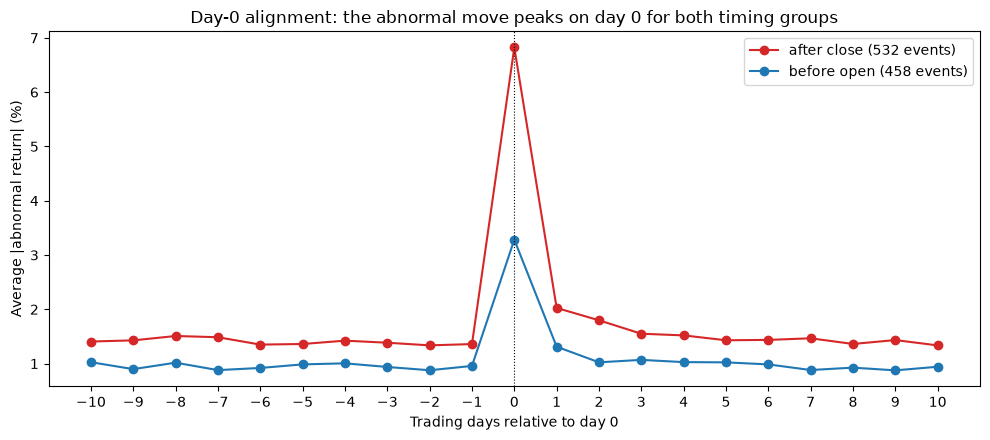

Day with the largest average |AR|: {'after close': 0, 'before open': 0, 'during market': 1}
During-market events (3), average |AR| on days 0 and +1 (%): {0: 1.55, 1: 10.74}


In [22]:
abs_ar = ar.assign(abs_ar=ar["ar"].abs() * 100).groupby(["timing", "rel_day"])["abs_ar"].mean().unstack(0)
counts = windows["timing"].value_counts()
fig, ax = plt.subplots(figsize=(10, 4.5))
for t, col in [("after close", "C3"), ("before open", "C0")]:
    ax.plot(abs_ar.index, abs_ar[t], marker="o", color=col, label=f"{t} ({counts[t]} events)")
ax.axvline(0, color="black", lw=0.8, ls=":")
ax.set_xticks(abs_ar.index)
ax.set_xlabel("Trading days relative to day 0")
ax.set_ylabel("Average |abnormal return| (%)")
ax.set_title("Day-0 alignment: the abnormal move peaks on day 0 for both timing groups")
ax.legend()
plt.tight_layout()
plt.savefig(f"{REPORTS}/day0_alignment.png", dpi=150)
plt.show()

peak = abs_ar.idxmax()
print("Day with the largest average |AR|:", peak.to_dict())
print("During-market events (3), average |AR| on days 0 and +1 (%):", abs_ar.loc[[0, 1], "during market"].round(2).to_dict())

### 3.6 Robustness: market-adjusted model
The same CARs with β fixed at 1 and α at 0 (normal return = SPY's return), the alternative named in Task 1.

In [23]:
ar_ma, _ = compute_abnormal_returns(windows, stock_ret, mkt_ret, DESIGN, model="market_adjusted")
cars_ma = event_car_table(ar_ma, windows, DESIGN).set_index("event_id")
comp = pd.DataFrame({
    "market model (bp)": cars.groupby("surprise_sign")["CAR(-1,+1)"].mean() * 1e4,
    "market-adjusted (bp)": cars_ma.groupby("surprise_sign")["CAR(-1,+1)"].mean() * 1e4,
}).loc[by_sign.index]
display(comp.round(1))
print(f"Correlation of event CAR(-1,+1) across the two models: "
      f"{cars.set_index('event_id')['CAR(-1,+1)'].corr(cars_ma['CAR(-1,+1)']):.3f}")

,market model (bp),market-adjusted (bp)
surprise_sign,,
positive,97.6,106.5
negative,-345.5,-333.7
zero,-312.9,-279.6
no estimate,-551.8,-290.1


Correlation of event CAR(-1,+1) across the two models: 0.988


### 3.7 Notes
- **Market model fits:** α and β were estimated separately for all 993 events on their own 221-day estimation windows. The median β is 1.02 (middle half 0.64–1.45) and the median R² is 0.29, so SPY explains about 30% of a typical stock's daily moves.
- **Tables:** `data/events/abnormal_returns.csv` holds 20,853 rows (993 events × 21 days) of AR; `data/events/event_cars.csv` holds each event's AR(0) and CARs; `reports/week4/aar_caar.csv` and `reports/week4/car_by_surprise.csv` hold the averages.
- **Hand checks:** for three events (MU July 2021 after close, JPM July 2021 before open, and ORCL September 2025, the largest day-0 move at +35%), β, AR(0) and CAR(−1, +1) rebuilt straight from prices match the functions to 15 decimal places.
- **Bookkeeping:** every CAR(−1, +1) is exactly AR(−1) + AR(0) + AR(+1), every CAR(+2, +10) exactly the 9 days +2 to +10, and every event has all 21 days.
- **Day-0 alignment:** the average absolute abnormal return peaks on day 0 for both after-close (6.8%) and before-open (3.3%) announcements, 3–5 times a normal day, so the reaction is not shifted by a session. The 3 "during market" events peak on day +1, which confirms they were really after-close releases with a wrong Yahoo time; CAR(−1, +1) still captures them.
- **First look (plain averages, untested):** CAR(−1, +1) averages +98 bp for positive surprises and −346 bp for negative ones, in the direction H1 predicts. Task 4 tests whether these are significant and large enough to matter.
- **Robustness:** the market-adjusted model gives almost the same CARs (correlation 0.988 across events), so the result does not hinge on the normal-return model.